# Gaming vs Academic Performance — Full Data Test & Insight Notebook
Notebook ini menguji seluruh tahap data (raw → ETL → DW → DM), memvalidasi kualitas data,
menghitung korelasi, menggali insight, dan melatih ulang model data mining.

**Struktur notebook:**
1. Load & validasi semua file (raw, ETL, DW, DM)
2. Data quality check (missing value, duplikasi, tipe data)
3. Statistik deskriptif
4. Analisis korelasi terhadap `grades`
5. Analisis tersegmentasi (binning) untuk tiap variabel penting
6. Visualisasi (heatmap, scatter+trendline, bar chart)
7. Data Mining: Random Forest Regressor (retrain dengan stress_level yang sudah bersih)
8. Ringkasan insight otomatis (dicetak dari hasil perhitungan, bukan hardcode)


## 1. Import Library & Load Semua Dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

raw = pd.read_csv("Gaming_Academic_Performance.csv")
etl = pd.read_csv("Gaming_Academic_Performance_ETL.csv")
dw  = pd.read_csv("Gaming_Academic_Performance_DW.csv")
dm  = pd.read_csv("Gaming_Academic_Performance_DM.csv")

print("raw:", raw.shape)
print("etl:", etl.shape)
print("dw :", dw.shape)
print("dm :", dm.shape)


raw: (8000, 14)
etl: (8000, 14)
dw : (8000, 14)
dm : (8000, 15)


## 2. Data Quality Check\nMemastikan tidak ada missing value tersembunyi (termasuk bug `stress_level` yang pernah ditemukan) dan tidak ada duplikasi.

In [5]:
def quality_report(df, name):
    print(f"===== {name} =====")
    print("Missing value per kolom:")
    miss = df.isnull().sum()
    print(miss[miss > 0] if miss.sum() > 0 else "  Tidak ada missing value.")
    print(f"Jumlah baris duplikat: {df.duplicated().sum()}")
    print(f"Jumlah student_id unik: {df['student_id'].nunique() if 'student_id' in df.columns else 'N/A'}")
    print()

for name, df in [("RAW", raw), ("ETL", etl), ("DW", dw), ("DM", dm)]:
    quality_report(df, name)


===== RAW =====
Missing value per kolom:
  Tidak ada missing value.
Jumlah baris duplikat: 0
Jumlah student_id unik: 8000

===== ETL =====
Missing value per kolom:
  Tidak ada missing value.
Jumlah baris duplikat: 0
Jumlah student_id unik: 8000

===== DW =====
Missing value per kolom:
  Tidak ada missing value.
Jumlah baris duplikat: 0
Jumlah student_id unik: 8000

===== DM =====
Missing value per kolom:
  Tidak ada missing value.
Jumlah baris duplikat: 0
Jumlah student_id unik: N/A



In [6]:
# Cek khusus kolom stress_level di dataset DM (pernah ditemukan bug NaN akibat double-run cell)
assert dm["stress_level"].isnull().sum() == 0, "stress_level masih mengandung NaN! Cek ulang proses ETL."
print("OK: stress_level di dataset DM sudah bersih (tidak ada NaN).")
print(dm["stress_level"].value_counts().sort_index())


OK: stress_level di dataset DM sudah bersih (tidak ada NaN).
stress_level
0    2743
1    4247
2    1010
Name: count, dtype: int64


## 3. Statistik Deskriptif

In [7]:
display(raw.describe(include="number").T)


,count,mean,std,min,25%,50%,75%,max
student_id,8000.0,4000.500000,2309.545410,1.00,2000.750000,4000.500,6000.250000,8000.000000
age,8000.0,19.983625,2.587072,16.00,18.000000,20.000,22.000000,24.000000
gaming_hours,8000.0,4.076562,2.297137,0.00,2.130000,4.130,6.040000,8.000000
study_hours,8000.0,5.448730,2.559515,1.00,3.240000,5.460,7.640000,10.000000
sleep_hours,8000.0,6.482910,1.431871,4.00,5.240000,6.500,7.690000,9.000000
attendance,8000.0,79.886525,11.580419,60.00,69.780000,79.695,90.100000,100.000000
social_activity,8000.0,2.507790,1.441128,0.00,1.287500,2.500,3.760000,5.000000
device_usage,8000.0,7.586315,2.710035,1.10,5.560000,7.610,9.600000,13.950000
reaction_time_ms,8000.0,271.105839,29.440675,183.26,247.160000,270.475,294.690000,347.870000
addiction_score,8000.0,9.908492,5.035837,-4.51,5.920000,10.005,13.860000,23.160000


In [8]:
display(raw.describe(include="object").T)


,count,unique,top,freq
gender,8000,3,Male,3904
gaming_genre,8000,3,FPS,3187
stress_level,8000,3,Medium,4247


## 4. Analisis Korelasi terhadap `grades`\nMenggunakan dataset DM (semua kolom sudah numerik).

In [9]:
num_cols = ["age","gaming_hours","study_hours","sleep_hours","attendance",
            "social_activity","device_usage","reaction_time_ms","addiction_score",
            "stress_level","grades"]

corr_matrix = dm[num_cols].corr()
corr_with_grades = corr_matrix["grades"].drop("grades").sort_values(key=abs, ascending=False)

print("Korelasi setiap variabel terhadap grades (diurutkan berdasarkan kekuatan hubungan):")
print(corr_with_grades)


Korelasi setiap variabel terhadap grades (diurutkan berdasarkan kekuatan hubungan):
study_hours         0.734040
gaming_hours       -0.557191
reaction_time_ms    0.517340
stress_level        0.495918
addiction_score    -0.495055
device_usage       -0.468472
sleep_hours         0.246285
attendance          0.130842
social_activity    -0.018717
age                 0.008052
Name: grades, dtype: float64


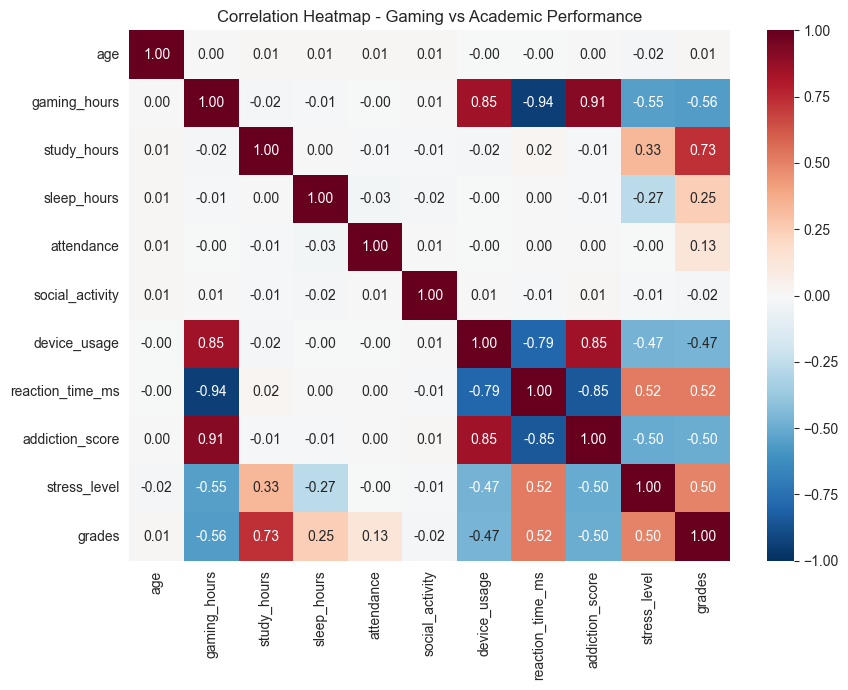

In [10]:
plt.figure(figsize=(9,7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation Heatmap - Gaming vs Academic Performance")
plt.tight_layout()
plt.savefig("insight_heatmap_correlation.png")
plt.show()


## 5. Analisis Tersegmentasi (Binning)\nMelihat rata-rata `grades` pada rentang nilai tertentu untuk variabel-variabel kunci.

In [11]:
def binned_mean(df, col, bins, label):
    tmp = df.copy()
    tmp["_bin"] = pd.cut(tmp[col], bins=bins)
    result = tmp.groupby("_bin", observed=True)["grades"].agg(["mean","count"]).round(2)
    print(f"--- Rata-rata grades berdasarkan {label} ---")
    print(result)
    print()
    return result

gaming_bin   = binned_mean(dm, "gaming_hours",   [0,1,2,3,4,5,6,7,8,20], "gaming_hours")
study_bin    = binned_mean(dm, "study_hours",    [0,1,2,3,4,5,6,7,8,20], "study_hours")
sleep_bin    = binned_mean(dm, "sleep_hours",    [0,4,5,6,7,8,9,12],     "sleep_hours")
addiction_bin= binned_mean(dm, "addiction_score",5,                     "addiction_score")


--- Rata-rata grades berdasarkan gaming_hours ---
         mean  count
_bin                
(0, 1]  81.61    976
(1, 2]  82.89    920
(2, 3]  74.84    970
(3, 4]  69.82    974
(4, 5]  64.58   1022
(5, 6]  60.73   1086
(6, 7]  54.23   1040
(7, 8]  43.71   1004

--- Rata-rata grades berdasarkan study_hours ---
          mean  count
_bin                 
(0, 1]   40.00      7
(1, 2]   41.99    899
(2, 3]   47.94    877
(3, 4]   52.93    922
(4, 5]   59.32    922
(5, 6]   65.07    859
(6, 7]   72.33    947
(7, 8]   80.65    865
(8, 20]  89.14   1702

--- Rata-rata grades berdasarkan sleep_hours ---
         mean  count
_bin                
(0, 4]  51.36      8
(4, 5]  58.57   1607
(5, 6]  61.86   1608
(6, 7]  66.62   1606
(7, 8]  71.16   1645
(8, 9]  73.00   1526

--- Rata-rata grades berdasarkan addiction_score ---
                   mean  count
_bin                          
(-4.538, 1.024]   81.48    238
(1.024, 6.558]    79.75   2048
(6.558, 12.092]   68.03   2844
(12.092, 17.626]  54.

In [12]:
print("--- Rata-rata grades berdasarkan stress_level (label asli) ---")
print(raw.groupby("stress_level")["grades"].agg(["mean","count"]).round(2))
print()
print("--- Rata-rata grades berdasarkan gaming_genre ---")
print(raw.groupby("gaming_genre")["grades"].agg(["mean","count"]).round(2))
print()
print("--- Rata-rata grades berdasarkan gender ---")
print(raw.groupby("gender")["grades"].agg(["mean","count"]).round(2))


--- Rata-rata grades berdasarkan stress_level (label asli) ---
               mean  count
stress_level              
High          81.02   1010
Low           50.57   2743
Medium        72.73   4247

--- Rata-rata grades berdasarkan gaming_genre ---
               mean  count
gaming_genre              
Casual        66.44   2405
FPS           66.15   3187
RPG           65.96   2408

--- Rata-rata grades berdasarkan gender ---
         mean  count
gender              
Female  66.58   3803
Male    65.86   3904
Other   65.32    293


In [13]:
# Cek cluster "intensitas gaming": gaming_hours, addiction_score, device_usage
cluster_cols = ["gaming_hours","addiction_score","device_usage"]
print("Korelasi antar variabel intensitas gaming:")
print(dm[cluster_cols].corr().round(3))


Korelasi antar variabel intensitas gaming:
                 gaming_hours  addiction_score  device_usage
gaming_hours            1.000            0.909         0.847
addiction_score         0.909            1.000         0.847
device_usage            0.847            0.847         1.000


## 6. Visualisasi Pendukung Insight

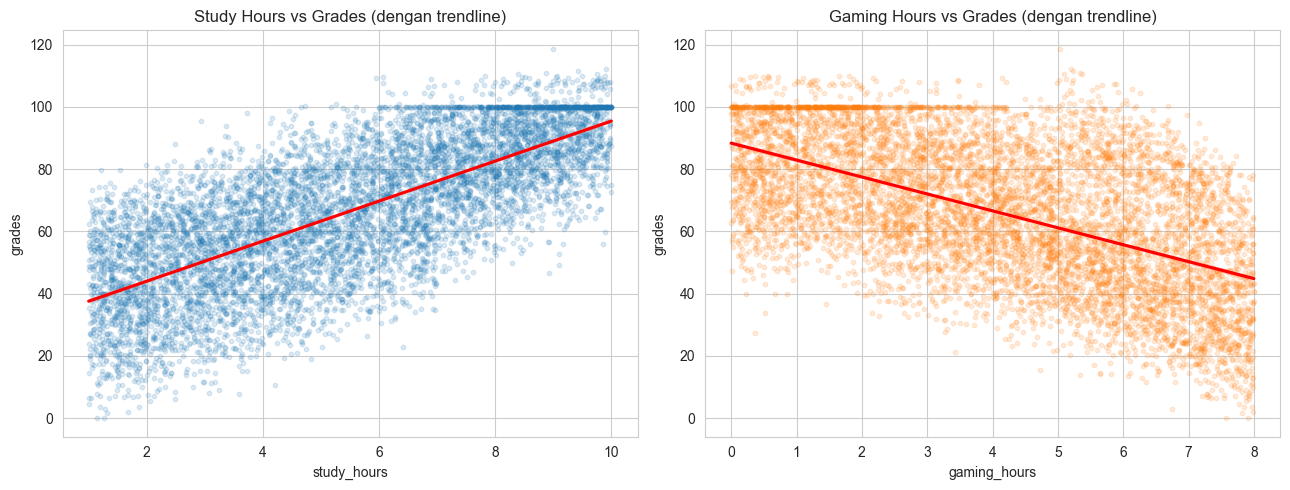

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))

sns.regplot(data=dm, x="study_hours", y="grades", ax=axes[0],
            scatter_kws={"alpha":0.15, "s":10, "color":"#1f77b4"},
            line_kws={"color":"red"})
axes[0].set_title("Study Hours vs Grades (dengan trendline)")

sns.regplot(data=dm, x="gaming_hours", y="grades", ax=axes[1],
            scatter_kws={"alpha":0.15, "s":10, "color":"#ff7f0e"},
            line_kws={"color":"red"})
axes[1].set_title("Gaming Hours vs Grades (dengan trendline)")

plt.tight_layout()
plt.savefig("insight_scatter_trendline.png")
plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_18116\3936604487.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=raw, x="stress_level", y="grades", order=order,


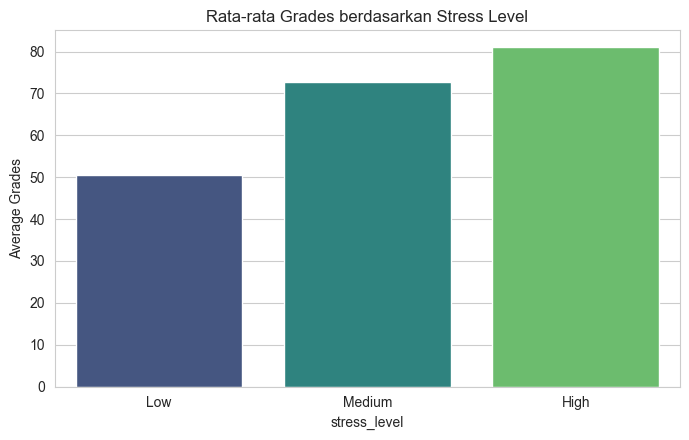

In [15]:
plt.figure(figsize=(7,4.5))
order = ["Low","Medium","High"]
sns.barplot(data=raw, x="stress_level", y="grades", order=order,
            estimator=np.mean, errorbar=None, palette="viridis")
plt.title("Rata-rata Grades berdasarkan Stress Level")
plt.ylabel("Average Grades")
plt.tight_layout()
plt.savefig("insight_bar_stress_grades.png")
plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_18116\3796515890.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=raw, x="gaming_genre", y="grades",


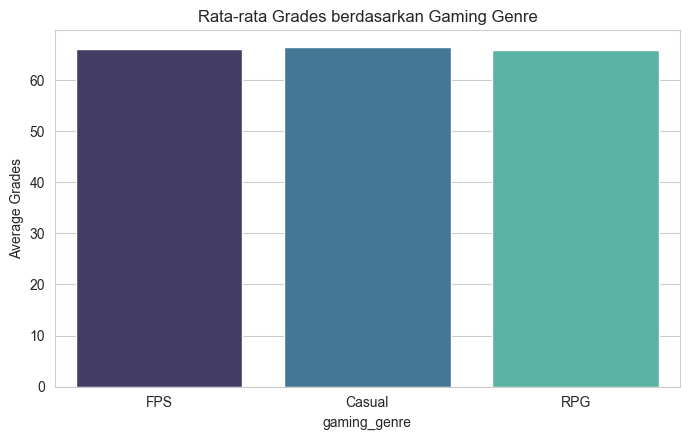

In [16]:
plt.figure(figsize=(7,4.5))
sns.barplot(data=raw, x="gaming_genre", y="grades",
            estimator=np.mean, errorbar=None, palette="mako")
plt.title("Rata-rata Grades berdasarkan Gaming Genre")
plt.ylabel("Average Grades")
plt.tight_layout()
plt.savefig("insight_bar_genre_grades.png")
plt.show()


## 7. Data Mining — Random Forest Regressor (Retrain)\nModel diprediksi terhadap `grades` menggunakan dataset DM yang sudah bersih (stress_level tidak lagi NaN).

In [17]:
feature_cols = [c for c in dm.columns if c != "grades"]
X = dm[feature_cols]
y = dm["grades"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print(f"R2 Score : {r2:.4f}  ({r2*100:.2f}%)")
print(f"MAE      : {mae:.4f}")
print(f"RMSE     : {rmse:.4f}")


R2 Score : 0.9248  (92.48%)
MAE      : 4.7732
RMSE     : 6.1173


Feature importance (Random Forest):
study_hours            0.555644
gaming_hours           0.318703
sleep_hours            0.065077
attendance             0.027300
reaction_time_ms       0.006815
social_activity        0.006265
device_usage           0.006201
addiction_score        0.006118
age                    0.003665
gender                 0.001143
stress_level           0.000850
gaming_genre_RPG       0.000750
gaming_genre_Casual    0.000745
gaming_genre_FPS       0.000723
dtype: float64


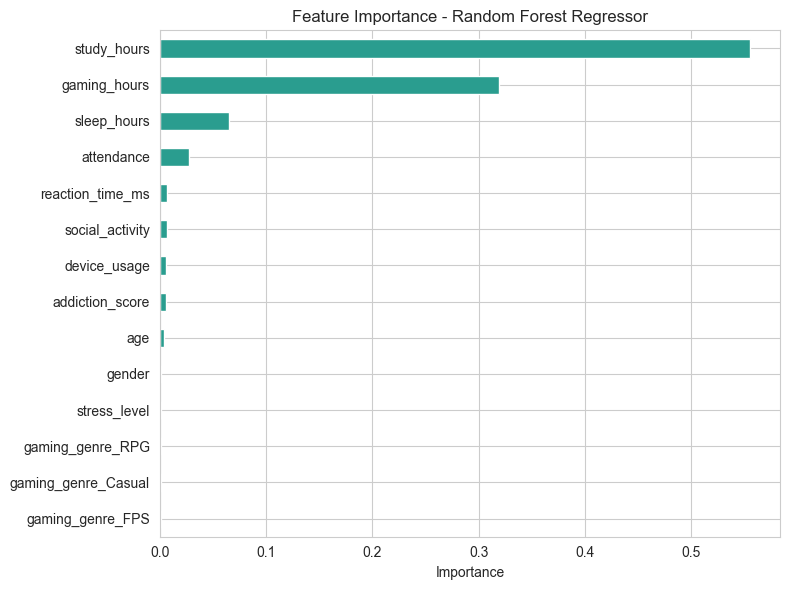

In [18]:
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("Feature importance (Random Forest):")
print(importances)

plt.figure(figsize=(8,6))
importances.plot(kind="barh", color="#2a9d8f")
plt.gca().invert_yaxis()
plt.title("Feature Importance - Random Forest Regressor")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("insight_feature_importance.png")
plt.show()


## 8. Ringkasan Insight (Otomatis, berdasarkan hasil perhitungan di atas)

In [19]:
top_corr = corr_with_grades.head(3)
strongest_positive = corr_with_grades[corr_with_grades > 0].idxmax()
strongest_negative = corr_with_grades[corr_with_grades < 0].idxmin()
top_feature_rf = importances.idxmax()

print("="*70)
print("RINGKASAN INSIGHT - Gaming vs Academic Performance")
print("="*70)
print(f"1. Variabel dengan korelasi POSITIF terkuat terhadap grades : {strongest_positive} (r={corr_with_grades[strongest_positive]:.3f})")
print(f"2. Variabel dengan korelasi NEGATIF terkuat terhadap grades : {strongest_negative} (r={corr_with_grades[strongest_negative]:.3f})")
print(f"3. Fitur paling penting menurut model Random Forest         : {top_feature_rf} (importance={importances[top_feature_rf]:.3f})")
print(f"4. Performa model prediksi grades (Random Forest)           : R2 = {r2*100:.2f}%, MAE = {mae:.2f}")
print(f"5. gaming_hours, addiction_score, device_usage saling berkorelasi kuat")
print(f"   (r > 0.8 satu sama lain) -> membentuk satu 'cluster intensitas gaming'.")
print("="*70)
print("\nCatatan: Jalankan seluruh notebook ini dari atas ke bawah (Restart & Run All)")
print("agar tidak terjadi bug 'double execution' seperti yang pernah ditemukan pada")
print("proses ETL sebelumnya (kolom stress_level sempat menjadi NaN karena cell")
print("dijalankan dua kali).")


RINGKASAN INSIGHT - Gaming vs Academic Performance
1. Variabel dengan korelasi POSITIF terkuat terhadap grades : study_hours (r=0.734)
2. Variabel dengan korelasi NEGATIF terkuat terhadap grades : gaming_hours (r=-0.557)
3. Fitur paling penting menurut model Random Forest         : study_hours (importance=0.556)
4. Performa model prediksi grades (Random Forest)           : R2 = 92.48%, MAE = 4.77
5. gaming_hours, addiction_score, device_usage saling berkorelasi kuat
   (r > 0.8 satu sama lain) -> membentuk satu 'cluster intensitas gaming'.

Catatan: Jalankan seluruh notebook ini dari atas ke bawah (Restart & Run All)
agar tidak terjadi bug 'double execution' seperti yang pernah ditemukan pada
proses ETL sebelumnya (kolom stress_level sempat menjadi NaN karena cell
dijalankan dua kali).
